## SI-C for MFA calculation, case study O'ahu

#### Definition of the MFA system  
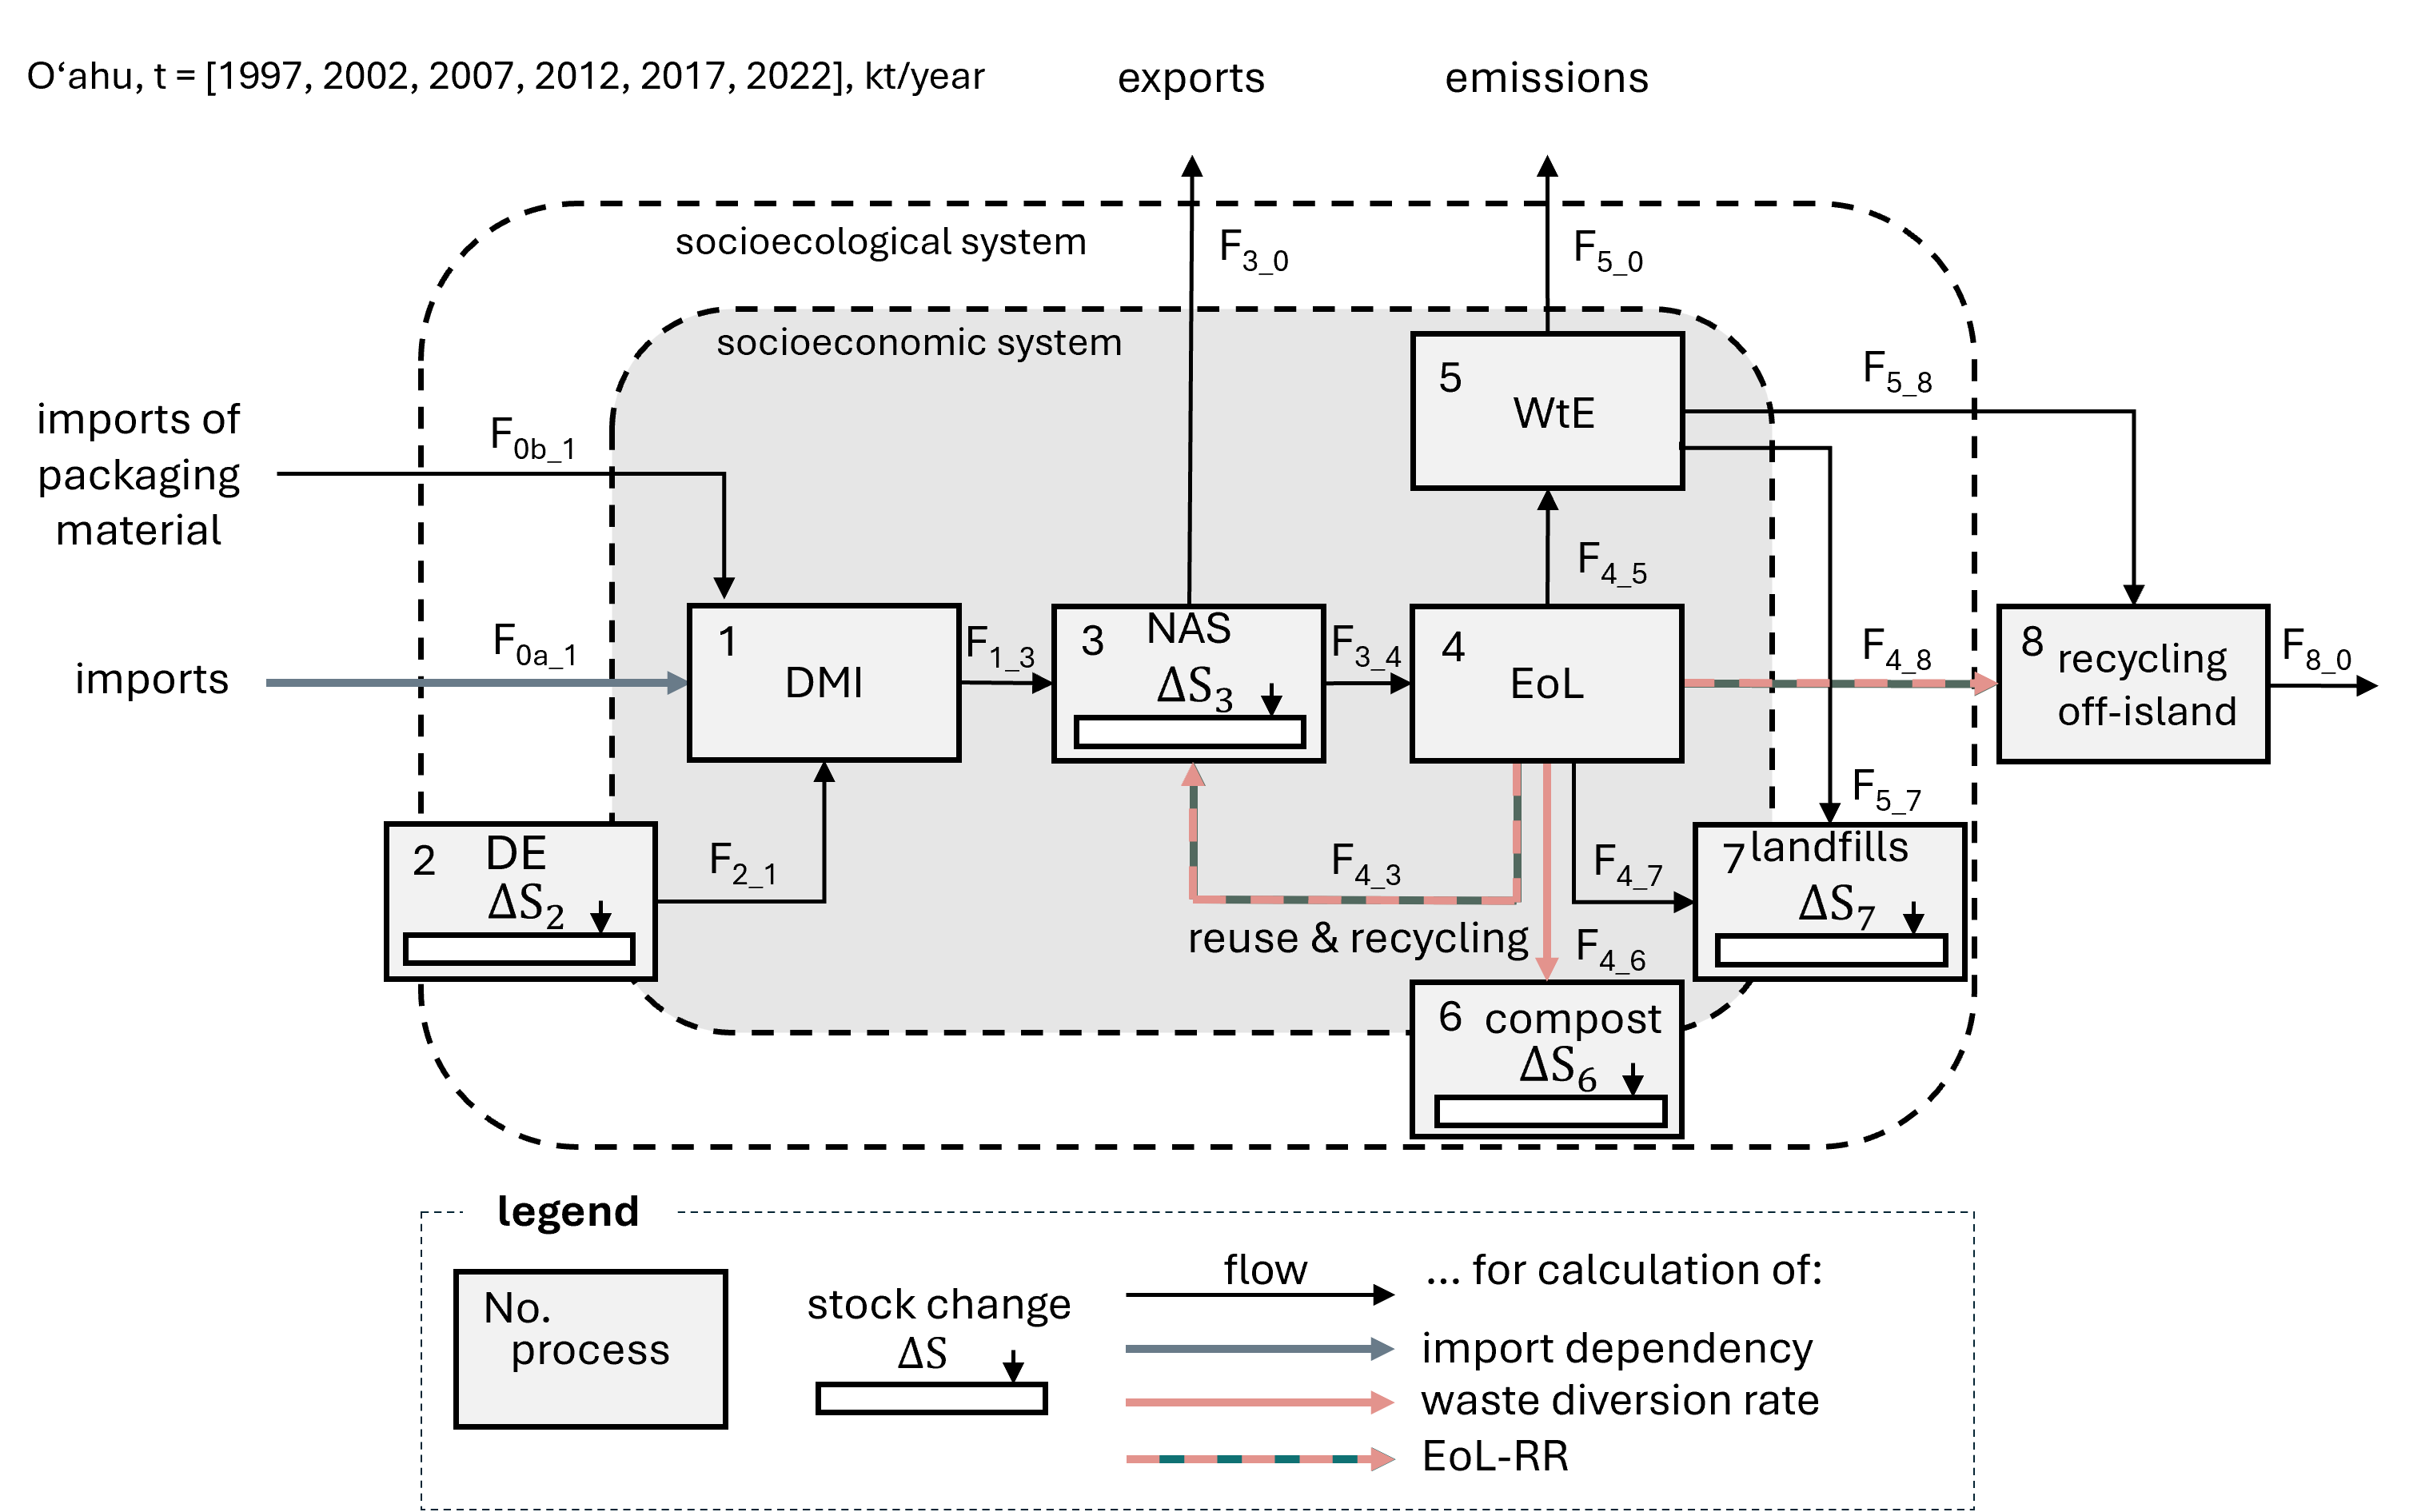




* DMI: Domestic Material Input = sum of imports, domestic extraction and imports of packaging material
* NAS: Net Additions to Stock = sum of DMI, reuse, minus exports (commodity flows) and EoL
* EoL: End-of-Life = sum of WtE, composting, reuse, landfills and recycling off island
* recycling off island = sum of metal recovery from WtE, and "recycled" materials defined by DOH
* landfills = sum of residual wastes and ashes from WtE, and EoL > landfill flow
* compost = "recycled" materials defined by DOH, if green waste or food waste  

Mass Balance Equations:
* DMI: F1_3 = F0a_1 + F0b_1 + F1_2
* NAS: deltaS3 = F1_3 + F4_3 - F3_0 - F3_4
* EoL: F3_4 = F4_5 + F4_6 + F4_7 + F4_8
* recycling off island: F8_0 = F4_8 + F5_8
* landfills: deltaS7 = F4_7 + F5_7
* compost: deltaS6 = F4_6

with: 
* 0: exports
* 0a: imports
* 0b: imports of packaging
* 1: DMI
* 2: DE
* 3: NAS
* 4: EoL
* 5: WtE
* 6: compost
* 7: landfills
* 8: recycling off-island

For some material flows, material composition is unknown. Based on information, we assume shares that are applied on flows. Following flows need parameters:  
* *a*: waste composition WtE (*m, t*)
* *b*: waste composition landfills (*m, t*)
* *c*: share of packaging material in WtE and landfill (*m, t*)
* *d*: share of post-combustion recovered metals
* (*e*: share of residual waste and ashes from total WtE) > not considered in O'ahu study, as data was available
* *f*: share of mining related emissions of Oahu from total Hawaii

#### Data preparation  
Different data sources are needed to calculate the flows. Also, there are several data gaps that need further treatment.  
Treated data:  
* 0 & 1: FAF data > data selection to extract only Oahu specific data. For earlier years, only Hawaii specific data is available. Therefore, a share per material category is applied on years 1997-2012.
* 2: imports of packaging materials > data is not part of public trade data. Therefore, waste composition studies (*a* and *b*) are used, packaging materials extracted for 1998, 2007 and 2017. For the rest of the years, shares are applied > factor *c*
* 3: DE data is not available for Oahu. Mining specific information is calculated by a emission share of mining on Oahu > factor *d*; food extraction from agriculture follows a calculation using adjusted population numbers and mean consumption.
* 7: WtE > total numbers are available, waste composition studies are used for material compositions > factor *a*
* 8: recycling off-island > it is assumed that all materials that are stated as recycled by DOH is recycled off island, except commercial food waste and green waste
* 9: landfills > total numbers are available, waste composition studies are used for material compositions > factor *b*
* 10: see 8

Another important treatment is to find the biggest common denominator for all material categories. Data categories were applied following SI-A.

#### Definition of known flows

In [126]:
import pandas as pd 
import numpy as np

In [225]:
F0a_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="total_imp") #other data source
F2_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="DE_total")
F3_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="Holt_smoothing_exp")
F4_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="reuse_flows") #precalculated data, based on F8_0 and C&D reuse
F4_6 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="total_recycling") #with m == "green waste"and"food"
P5 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "total_waste_DOH_data") #WtE MSW without composition, preprocessed from Otsu and C&C Honbolulu)
F8_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name="total_recycling") #with m != "green waste","food" and "final products"
F4_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "total_waste_DOH_data") #MSW and C&D landfill, including backcast
F5_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "total_waste_DOH_data") #ash & residue, including estimation based on WtE and share 2005-2011

#### Factors

In [228]:
a1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor a1") #2006, WtE
a2 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor a2") #2017, WtE+landfill
b1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor b1") #2006, landfill
b2 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor a2") #2017, WtE+landfill
b3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor b3") #1998, landfill
c1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor c1") #2006, WtE
c2 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor c2") #2017, WtE+landfill
c3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor b3") #1998, landfill
#d = metal recovery
#e = residual wastes and ashes

##### a: WtE waste composition

In [231]:
factors_a1 = a1.copy().dropna().rename(columns={'mean tons': 'Tons'})
factors_a2 = a2.copy().dropna().rename(columns={'est tons': 'Tons'})
factors_a1["share"] = factors_a1['Tons']/factors_a1['Tons'].sum()
factors_a2["share"] = factors_a2['Tons']/factors_a2['Tons'].sum()

mean_df = (
    pd.concat([factors_a1, factors_a2])
    .groupby("Material", as_index=False)['Tons']
    .mean()
    .assign(Year=2012)
)
mean_df = mean_df[(mean_df['Material'] != "sewage sludge")] #no sewage sludge was received in 2012, started in 2015
mean_df['share'] = mean_df['Tons']/mean_df['Tons'].sum()
mean_df = mean_df.drop('Tons', axis=1)

factors_a1 = (
    factors_a1
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_a2 = (
    factors_a2
    .groupby("Material", as_index = False)["share"]
    .sum()
)

df1_all = pd.concat([
    factors_a1.assign(Year=2007),
    factors_a1.assign(Year=1997),
    factors_a1.assign(Year=2002)
], ignore_index=True)

df2_all = pd.concat([
    factors_a2.assign(Year=2017),
    factors_a2.assign(Year=2022)
], ignore_index=True)

#final WtE composition factor a
a = pd.concat( 
    [df1_all, mean_df, df2_all],
    ignore_index=True
)
a["Year"] = pd.to_numeric(a["Year"], errors="coerce").astype("Int64")
a.head()

,Material,share,Year
0,chemicals,0.002614,2007
1,construction material and minerals,0.024270,2007
2,electronics,0.026743,2007
3,final products,0.052471,2007
4,food,0.199520,2007


##### b: landfill waste composition

In [234]:
factors_b1 = b1.copy().dropna().rename(columns={'mean tons': 'Tons'})
factors_b2 = b2.copy().dropna().rename(columns={'est tons': 'Tons'})
factors_b3 = b3.copy().dropna()
factors_b1["share"] = factors_b1['Tons']/factors_b1['Tons'].sum()
factors_b2["share"] = factors_b2['Tons']/factors_b2['Tons'].sum()
factors_b3["share"] = factors_b3['Tons']/factors_b3['Tons'].sum()


#waste composition 2012: share of 2006 and 2017 information
mean_df = (
    pd.concat([factors_b1, factors_b2])
    .groupby("Material", as_index=False)['Tons']
    .mean()
    .assign(Year=2012)
)

mean_df['share'] = mean_df['Tons']/mean_df['Tons'].sum()
mean_df.loc[mean_df["Material"] == "sewage sludge", "share"] = (
    factors_b2
        .loc[factors_b2["Material"] == "sewage sludge", "share"]
        .iloc[0]
)
mean_df = mean_df.drop('Tons', axis=1)

factors_b1 = (
    factors_b1
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b2 = (
    factors_b2
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b3 = (
    factors_b3
    .groupby("Material", as_index = False)["share"]
    .sum()
)
df1_all = pd.concat([
    factors_b1.assign(Year=2007),
    factors_b1.assign(Year=2002)
], ignore_index=True)

df2_all = pd.concat([
    factors_b2.assign(Year=2017),
    factors_b2.assign(Year=2022)
], ignore_index=True)

df3_all = pd.concat([
    factors_b3.assign(Year=1997)
], ignore_index=True)

#final landfill waste composition factor b
b = pd.concat( 
    [df3_all, df1_all, mean_df, df2_all],
    ignore_index=True
)
b["Year"] = pd.to_numeric(b["Year"], errors="coerce").astype("Int64")
b.head()

,Material,share,Year
0,construction material and minerals,0.200436,1997
1,final products,0.096206,1997
2,glass,0.005008,1997
3,green waste,0.060131,1997
4,metals,0.123110,1997


##### c: Application of Packaging Factor (landfill / WtE)

In [237]:
df_packaging_c1 = c1[c1["packaging"] == 1]
factors_c1 = (
    df_packaging_c1
    .groupby("Material", as_index = False)["factor"]
    .sum()
)
factors_c1["Year"] = 2007

df_packaging_c2 = c2[c2["packaging"] == 1]
factors_c2 = (
    df_packaging_c2
    .groupby("Material", as_index = False)["factor"]
    .sum()
)
factors_c2["Year"] = 2017

df_packaging_c3 = c3[c3["packaging"] == 1]
factors_c3 = (
    df_packaging_c3
    .groupby("Material", as_index = False)["factor"]
    .sum()
)
factors_c3["Year"] = 1997

df1_all = pd.concat([
    factors_c1.assign(Year=2002),
    factors_c1 #2007
], ignore_index=True)

df2_all = pd.concat([
    factors_c2, #2017
    factors_c2.assign(Year=2022)
], ignore_index=True)

df3_all = pd.concat([
    factors_c3 #1997
], ignore_index=True)

mean_df = (
    pd.concat([factors_c1, factors_c2])
    .groupby("Material", as_index=False)["factor"]
    .mean()
    .assign(Year=2012)
)
#final packaging factor c
c = pd.concat( 
    [df3_all, df1_all, mean_df, df2_all],
    ignore_index=True
)
c.head()

,Material,factor,Year
0,glass,0.005,1997
1,metals,0.004,1997
2,paper,0.052,1997
3,plastic,0.025,1997
4,wood,0.076,1997


##### d: Metal recovery from WtE - post combustion, ferrous  
In this study, we assume that all metals entering the WtE, and recognized by the waste composition study - are also leaving the WtE as metals, because they are pre-combustion extracted and therefore recovered.  
But there are also metal components that are extracted post-combustion, as they can be part of products' material composition. We use available information on post-combustion ferrous metals recovered in 2005 and 2006, to calculate factor d. Factor d needs to be applied on F4_5, after excluding metals.  

__Operating data for H-POWER (tons)__ (Eckelman & Chertow 2009, p. 37)
|                                 |  2005  |  2006  |
|---------------------------------|--------|--------|
|Solid Waste Processed            |552,265 |643,895 |
|Unprocessible Waste Removed      |5,891   |4,894   |
|Pre-combustion Ferrous Removed   |12,748  |14,445  |
|Ash Removed                      |84,349  |92,052  |
|Post-combustion Ferrous          |4,135   |5,401   |
|Gross MWH Produced               |336,472 |386,077 |
|Net MWh Sold                     |292,252 |338,077 |
|Lime Consumed                    |5,037   |5,544   |  



In [240]:
share2005 = 4135/(552265-12748)
share2006 = 5401/(643895-14445)
d = (share2005+share2006)/2  
print(d)

0.008122384728105995


## Modelling of Output data  
In this section, we model all output data, including EoL, WtE, Recycling off island, landfills, composting and reuse.  
Before running the calculations, make sure, your input data follows the same structure.  
* F3_4 (total EoL), F3_4 = F4_3 + F4_5 + F4_6 + F4_7
* F4_5 (WtE), F4_5 = P5*a
* F5_8 (WtE metal recovery) = F4_5(excl metals)*d + F4_5(metals)
* F5_7 (WtE residual wastes and ashes) = P5*e
* F4_8 = F8_0 - F5_8
* deltaS7 = F4_7*b + F5_7
* deltaS6 = already defined by flow F4_6
* F4_3 = already defined flow, including reuse on island

Calculation order: F4_5, F5_8, F5_7, F4_8, F4_6, F3_4

##### F4_5: WtE and composition

In [244]:
P5.head()

,year,C&D Recycling,C&D Landfill,general recycling (MSW),WtE (MSW),WtE (ash & residue),landfill (MSW),Trash Shipping (MSW),total tonnage,CY WtE (Otsu + C&C Honolulu),WtE (MSW) - WtE (Otsu)
0,1997,175859.290657,214388.0,NaN,NaN,186551.176305,312923.00,NaN,NaN,602357.5,NaN
1,1998,177231.817998,196089.5,NaN,NaN,189174.505041,268925.50,NaN,NaN,610828.0,NaN
2,1999,178604.345338,197717.0,NaN,NaN,186482.732217,270820.25,NaN,NaN,602136.5,NaN
3,2000,179976.872678,187695.0,NaN,NaN,179852.172442,318631.00,NaN,NaN,580727.0,NaN
4,2001,181349.400018,172076.0,NaN,NaN,163857.315482,337449.00,NaN,NaN,529081.0,NaN


In [246]:
P5 = P5.drop(columns={'C&D Recycling', 'C&D Landfill', 'general recycling (MSW)', 'WtE (MSW)', 'WtE (ash & residue)', 'landfill (MSW)', 'Trash Shipping (MSW)', 'total tonnage', 'WtE (MSW) - WtE (Otsu)'}).rename(columns={'year': 'Year', 'CY WtE (Otsu + C&C Honolulu)': 'Value'})

In [248]:
F4_5 = P5.merge(a, on = "Year", how = "inner")
# apply waste composition share a and convert to kilotons
F4_5['kilotons'] = F4_5['Value']*F4_5['share']/1000 
F4_5 = F4_5.drop(columns={'Value', 'share'})
# assign Source and Target
F4_5['Source'] = 'EoL'
F4_5['Target'] = 'WtE'
F4_5.head()
# F4_5.to_excel("[insert_your_path_here]/F4_5.xlsx", index=False)

,Year,Material,kilotons,Source,Target
0,1997,chemicals,1.574544,EoL,WtE
1,1997,construction material and minerals,14.619288,EoL,WtE
2,1997,electronics,16.108614,EoL,WtE
3,1997,final products,31.606365,EoL,WtE
4,1997,food,120.182236,EoL,WtE


##### F5_8 (WtE metal recovery) = F4_5(excl metals)*d + F4_5(metals)

In [251]:
pre_comb = F4_5[F4_5['Material'] == "metals"] #pre-combustion
# exclude metals from pre-combustion materials, assign post-combustion material share d on sum of other materials
post_comb = (
    F4_5
    .query("Material != 'metals'")
    .groupby(["Year", "Source", "Target"], as_index=False)
    .agg({"kilotons": "sum"})
    .assign(Material= "metals",
           kilotons=lambda x: x["kilotons"] * d) 
)
# convert to kilotons
F5_8 = pd.concat([pre_comb, post_comb], ignore_index=True).groupby(["Year", "Source", "Target", "Material"], as_index=False).agg({"kilotons": "sum"})
# assign Source and Target
F5_8['Source'] = 'WtE'
F5_8['Target'] = 'Recycling off island'
F5_8.head()
#F5_8.to_excel("[insert_your_path_here]/F5_8.xlsx", index=False)

,Year,Source,Target,Material,kilotons
0,1997,WtE,Recycling off island,metals,25.840004
1,2002,WtE,Recycling off island,metals,23.937001
2,2007,WtE,Recycling off island,metals,25.497120
3,2012,WtE,Recycling off island,metals,17.263233
4,2017,WtE,Recycling off island,metals,36.747878


##### F5_7 (residual waste and ashes)

In [254]:
F5_7.head()

,year,C&D Recycling,C&D Landfill,general recycling (MSW),WtE (MSW),WtE (ash & residue),landfill (MSW),Trash Shipping (MSW),total tonnage,CY WtE (Otsu + C&C Honolulu),WtE (MSW) - WtE (Otsu)
0,1997,175859.290657,214388.0,NaN,NaN,186551.176305,312923.00,NaN,NaN,602357.5,NaN
1,1998,177231.817998,196089.5,NaN,NaN,189174.505041,268925.50,NaN,NaN,610828.0,NaN
2,1999,178604.345338,197717.0,NaN,NaN,186482.732217,270820.25,NaN,NaN,602136.5,NaN
3,2000,179976.872678,187695.0,NaN,NaN,179852.172442,318631.00,NaN,NaN,580727.0,NaN
4,2001,181349.400018,172076.0,NaN,NaN,163857.315482,337449.00,NaN,NaN,529081.0,NaN


In [256]:
F5_7 = F5_7.drop(columns={'C&D Recycling', 'C&D Landfill', 'general recycling (MSW)', 'CY WtE (Otsu + C&C Honolulu)', 'WtE (MSW)', 'landfill (MSW)', 'Trash Shipping (MSW)', 'total tonnage', 'WtE (MSW) - WtE (Otsu)'}).rename(columns={'year': 'Year', 'WtE (ash & residue)': 'Value'})
# convert to kilotons
F5_7['Value'] = (F5_7['Value']/1000) 
F5_7 = F5_7.rename(columns={'Value': 'kilotons'})
# assign Source and Target, apply correct outflow material category (residual waste and ashes)
F5_7['Source'] = "WtE"
F5_7['Target'] = "landfills" 
F5_7['Material'] = "residual waste and ashes" 
F5_7.head()
#F5_7.to_excel("[insert_your_path_here]/F5_7.xlsx", index=False)

,Year,kilotons,Source,Target,Material
0,1997,186.551176,WtE,landfills,residual waste and ashes
1,1998,189.174505,WtE,landfills,residual waste and ashes
2,1999,186.482732,WtE,landfills,residual waste and ashes
3,2000,179.852172,WtE,landfills,residual waste and ashes
4,2001,163.857315,WtE,landfills,residual waste and ashes


##### F4_8 = F8_0 - F5_8 (Recycling off island, without WtE recovery)  
Exclude food, green waste, construction material and minerals, sewage sludge and final products, as we define 
* final products as reused on island,
* food and green waste composted on island,
* construction material and minerals recycled on island (aggregates) and
* sewage sludge treated on island.

In [259]:
# exclude irrelevant material categories
F8_0 = (F8_0
        .query("Material not in ['food', 'green waste', 'construction material and minerals', 'sewage sludge', 'final products']")) 
# convert to kilotons
F8_0['Tons'] = F8_0['Tons']/1000
F8_0 = F8_0.rename(columns={'Tons': 'kilotons'}) 
F8_0.head()
#F8_0.to_excel("[insert_your_path_here]/F8_0.xlsx", index=False)

,Material,Category,Year,kilotons
0,paper,Corrugated Cardboard,1997,31.4
1,paper,Newspaper,1997,13.2
2,paper,Office Paper,1997,4.5
3,paper,Other Paper,1997,8.4
4,metals,ferrous (includes autos),1997,116.0


In [261]:
F5_8.head()

,Year,Source,Target,Material,kilotons
0,1997,WtE,Recycling off island,metals,25.840004
1,2002,WtE,Recycling off island,metals,23.937001
2,2007,WtE,Recycling off island,metals,25.497120
3,2012,WtE,Recycling off island,metals,17.263233
4,2017,WtE,Recycling off island,metals,36.747878


In [263]:
F4_8 = F8_0.copy()
F4_8 = (
    F4_8
    .groupby(["Year","Material"],as_index=False)
    .agg({"kilotons": "sum"})
)

In [265]:
sub_by_year = (
    F5_8
    .groupby("Year")["kilotons"]
    .sum()
)
F5_8.head()
sub_by_year.head()

Year
1997    25.840004
2002    23.937001
2007    25.497120
2012    17.263233
2017    36.747878
Name: kilotons, dtype: float64

In [267]:
# select relevant material category
mask = F4_8["Material"] == "metals"

F4_8.loc[mask, "kilotons"] -= (
    F4_8.loc[mask, "Year"].map(sub_by_year).fillna(0)
)
# assign Source and Target
F4_8['Source'] = "EoL"
F4_8['Target'] = "Recycling off island"
F4_8.head()
#F4_8.to_excel("[insert_your_path_here]/F4_8.xlsx", index=False)

,Year,Material,kilotons,Source,Target
0,1997,electronics,0.000000,EoL,Recycling off island
1,1997,glass,11.000000,EoL,Recycling off island
2,1997,metals,99.659996,EoL,Recycling off island
3,1997,motorized vehicles,6.950000,EoL,Recycling off island
4,1997,paper,57.500000,EoL,Recycling off island


##### deltaS7 = F4_7*b + F5_7

In [270]:
F4_7 = F4_7.drop(columns={'C&D Recycling', 'general recycling (MSW)', 'WtE (ash & residue)', 'CY WtE (Otsu + C&C Honolulu)', 'WtE (MSW)', 'Trash Shipping (MSW)', 'total tonnage', 'WtE (MSW) - WtE (Otsu)'}).rename(columns={'year': 'Year'})
# assign Source and Target
F4_7['Source'] = "EoL"
F4_7['Target'] = "landfills" 
F4_7.head()

,Year,C&D Landfill,landfill (MSW),Source,Target
0,1997,214388.0,312923.00,EoL,landfills
1,1998,196089.5,268925.50,EoL,landfills
2,1999,197717.0,270820.25,EoL,landfills
3,2000,187695.0,318631.00,EoL,landfills
4,2001,172076.0,337449.00,EoL,landfills


In [272]:
# msw
msw = F4_7.drop(columns={'C&D Landfill'}).rename(columns={'landfill (MSW)': 'Tons'})
msw['Material'] = "msw"
# c&d
cd = F4_7.drop(columns={'landfill (MSW)'}).rename(columns={'C&D Landfill': 'Tons'})
cd['Material'] = 'construction material and minerals'

In [274]:
msw = msw.merge(b, on = "Year", how = "left") 
# convert to kilotons
msw['Tons'] = (msw['Tons']*msw['share'])/1000
msw = msw.rename(columns={'Tons': 'kilotons'})

In [276]:
msw = msw.rename(columns={'Material_y': 'Material'}).drop(columns={'Material_x','share'})
msw.head()

,Year,kilotons,Source,Target,Material
0,1997,62.721078,EoL,landfills,construction material and minerals
1,1997,30.105138,EoL,landfills,final products
2,1997,1.567211,EoL,landfills,glass
3,1997,18.816323,EoL,landfills,green waste
4,1997,38.523998,EoL,landfills,metals


In [278]:
# convert to kilotons
cd['Tons'] = cd['Tons'] / 1000
cd = cd.rename(columns={'Tons': 'kilotons'})
cd.head()

,Year,kilotons,Source,Target,Material
0,1997,214.3880,EoL,landfills,construction material and minerals
1,1998,196.0895,EoL,landfills,construction material and minerals
2,1999,197.7170,EoL,landfills,construction material and minerals
3,2000,187.6950,EoL,landfills,construction material and minerals
4,2001,172.0760,EoL,landfills,construction material and minerals


In [280]:
F4_7 = pd.concat([msw, cd], ignore_index = True)
F4_7.head()
#F4_7.to_excel("[insert_your_path_here]/F4_7.xlsx", index=False)

,Year,kilotons,Source,Target,Material
0,1997,62.721078,EoL,landfills,construction material and minerals
1,1997,30.105138,EoL,landfills,final products
2,1997,1.567211,EoL,landfills,glass
3,1997,18.816323,EoL,landfills,green waste
4,1997,38.523998,EoL,landfills,metals


In [282]:
deltaS7 = pd.concat([F4_7, F5_7],ignore_index=True)
#set Source and Target to NA, because this is not a flow
deltaS7['Source'] =  'NA'
deltaS7['Target'] =  'NA'
deltaS7.head()
#deltaS7.to_excel("[insert_your_path_here]/deltaS7.xlsx", index=False)

,Year,kilotons,Source,Target,Material
0,1997,62.721078,NA,NA,construction material and minerals
1,1997,30.105138,NA,NA,final products
2,1997,1.567211,NA,NA,glass
3,1997,18.816323,NA,NA,green waste
4,1997,38.523998,NA,NA,metals


##### F4_6 filtering for food, greenwaste and sewage sludges

In [285]:
F4_6.head()

,Material,Category,Year,Tons
0,paper,Corrugated Cardboard,1997,31400.0
1,paper,Newspaper,1997,13200.0
2,paper,Office Paper,1997,4500.0
3,paper,Other Paper,1997,8400.0
4,metals,ferrous (includes autos),1997,116000.0


In [287]:
# select relevant material categories
F4_6 = (F4_6
        .query("Material in ['food', 'green waste', 'sewage sludge']")) 
# convert to kilotons
F4_6['Tons'] = F4_6['Tons']/1000
F4_6 = F4_6.rename(columns={'Tons': 'kilotons'}).drop(columns={'Category'})
# assign Source and Target
F4_6['Source'] = 'EoL'
F4_6['Target'] = 'Composting'
F4_6.head()
#F4_6.to_excel("[insert_your_path_here]/F4_6.xlsx", index=False)

,Material,Year,kilotons,Source,Target
10,green waste,1997,52.300,EoL,Composting
12,food,1997,52.500,EoL,Composting
16,sewage sludge,1997,NaN,EoL,Composting
28,green waste,2002,62.732,EoL,Composting
30,food,2002,44.350,EoL,Composting


##### F3_4 (total EoL), F3_4 = F4_3 + F4_5 + F4_6 + F4_7

In [290]:
EoL = [F4_3, F4_5, F4_6, F4_7, F4_8]

In [292]:
F3_4 = pd.concat(EoL, ignore_index=True)

In [294]:
# convert to kilotons
F3_4 = (
    F3_4
    .groupby(["Year", "Material"], as_index=False)["kilotons"]
    .sum()
)
#assign Source and Target
F3_4['Source'] = 'NAS'
F3_4['Target'] = 'EoL'
F3_4.head()
#F3_4.to_excel("[insert_your_path_here]/F3_4.xlsx", index=False)

,Year,Material,kilotons,Source,Target
0,1997,chemicals,1.574544,NAS,EoL
1,1997,construction material and minerals,496.128366,NAS,EoL
2,1997,electronics,16.108614,NAS,EoL
3,1997,final products,69.211503,NAS,EoL
4,1997,food,172.682236,NAS,EoL


## Modelling of Input data  
Input data is partly dependent on output data, as DE for food is also calculated based on food waste, which is the total inflow / outflow to/from EoL with m = "food".
* F0a_1: imports #already defined
* F0b_1: imports of packaging
* F2_1: DE #already defined
* F1_3: DMI (F1_3 = F0a_1 + F0b_1 + F2_1)

F0b_1 = (F4_5 + F4_7)*c #composition shares  

In [298]:
# convert to kilotons
F0b_1 = (pd.concat([F4_5, F4_7])
        .groupby(["Year","Material"], as_index=False)['kilotons']
        .sum()
)
F0b_1 = F0b_1 .merge(
    c,
    on=["Material", "Year"],
    how="left"
)
F0b_1["factor"] = F0b_1["factor"].fillna(0)
# apply packaging factor c
F0b_1["kilotons"] = F0b_1["kilotons"] * F0b_1["factor"]
# assign Source and Target
F0b_1['Source'] = 'Indirect Imports of Packaging'
F0b_1['Target'] = 'DMI'
F0b_1 = F0b_1.drop(columns={'factor'})
#F0b_1.to_excel("[insert_your_path_here]/F0b_1_for_comparison.xlsx", index=False)

In [300]:
# add information on packaging materials, exported for recycling
F8_0.head()

,Material,Category,Year,kilotons
0,paper,Corrugated Cardboard,1997,31.4
1,paper,Newspaper,1997,13.2
2,paper,Office Paper,1997,4.5
3,paper,Other Paper,1997,8.4
4,metals,ferrous (includes autos),1997,116.0


In [302]:
category_to_keep=['Corrugated Cardboard', 'non-ferrous (includes aluminum)', 'Glass', 'Plastic']
F8_0_packaging = F8_0[F8_0["Category"].isin(category_to_keep)]

In [304]:
F8_0_packaging.head()
#F8_0_packaging.to_excel("[insert_your_path_here]/F8_0_pack_for_comparison.xlsx", index=False)

,Material,Category,Year,kilotons
0,paper,Corrugated Cardboard,1997,31.400
5,metals,non-ferrous (includes aluminum),1997,9.500
6,glass,Glass,1997,11.000
7,plastic,Plastic,1997,0.194
18,paper,Corrugated Cardboard,2002,38.030


In [306]:
F0b_1 = (pd.concat([F0b_1, F8_0_packaging])
        .groupby(["Year","Material"], as_index=False)['kilotons']
        .sum()
)
# assign Source and Target
F0b_1['Source'] = 'Indirect Imports of Packaging'
F0b_1['Target'] = 'DMI'
F0b_1.head()
#F0b_1.to_excel("[insert_your_path_here]/F0b_1.xlsx", index=False)

,Year,Material,kilotons,Source,Target
0,1997,chemicals,0.0,Indirect Imports of Packaging,DMI
1,1997,construction material and minerals,0.0,Indirect Imports of Packaging,DMI
2,1997,electronics,0.0,Indirect Imports of Packaging,DMI
3,1997,final products,0.0,Indirect Imports of Packaging,DMI
4,1997,food,0.0,Indirect Imports of Packaging,DMI


##### F1_2: DMI (F1_3 = F0a_1 + F0b_1 + F2_1)

In [309]:
F0a_1.head()
F0a_1 = F0a_1.rename(columns={'sctg2':'Material'})

In [311]:
F0a_1_long = F0a_1.copy()

In [313]:
F0a_1 = F0a_1_long.copy()
# assign Source and Target
F0a_1['Source'] = "Imports"
F0a_1['Target'] = "DMI"

Final calculation of DE food

In [316]:
food = F2_1.copy()
# select relevant material category
food = food[food['Material'] == 'food']

In [318]:
food_waste = F3_4.copy()
# select relevant material category
food_waste = food_waste[food_waste['Material'] == 'food']

In [322]:
display(food_waste, F2_1)

,Year,Material,kilotons,Source,Target
4,1997,food,172.682236,NAS,EoL
23,2002,food,162.458546,NAS,EoL
42,2007,food,153.434934,NAS,EoL
69,2012,food,256.338379,NAS,EoL
96,2017,food,248.068107,NAS,EoL
123,2022,food,254.857334,NAS,EoL


,Year,kilotons,Material,Source,Target
0,1997,324.750907,food,DE,DMI
1,2002,-182.756569,food,DE,DMI
2,2007,26.079400,food,DE,DMI
3,2012,340.224869,food,DE,DMI
4,2017,359.618464,food,DE,DMI
5,2022,200.944991,food,DE,DMI
6,1971,4675.389209,construction material and minerals,DE,DMI
7,1972,3810.352409,construction material and minerals,DE,DMI
8,1973,5382.534344,construction material and minerals,DE,DMI
9,1974,5857.705942,construction material and minerals,DE,DMI


In [324]:
# combine the two dataframes
de_food = pd.concat([food, food_waste]) 
de_food = de_food.groupby(['Year','Material'], as_index=False)["kilotons"].sum()
# assign Source and Target
de_food['Source'] = 'DE'
de_food['Target'] = 'DMI'
de_food.head()

,Year,Material,kilotons,Source,Target
0,1997,food,497.433144,DE,DMI
1,2002,food,-20.298023,DE,DMI
2,2007,food,179.514334,DE,DMI
3,2012,food,596.563248,DE,DMI
4,2017,food,607.686571,DE,DMI


In [335]:
# select relevant material category
de_cd = F2_1[F2_1['Material'] == 'construction material and minerals']
# combine the two dataframes
F2_1 = pd.concat([de_food,de_cd])
F2_1.head()
#F2_1.to_excel("[insert_your_path_here]/F2_1.xlsx", index=False)
#F2_1.to_excel("[insert_your_path_here]/F2_1_Holt.xlsx", index=False)

In [337]:
DMI = [F0a_1, F0b_1, F2_1]

In [339]:
F1_3 = (pd.concat(DMI, ignore_index=True)
        .groupby(["Year","Material"], as_index=False)['kilotons']
        .sum()
       )
# assign Source and Target
F1_3['Source'] = 'DMI'
F1_3['Target'] = 'NAS'
F1_3.head()
#F1_3.to_excel("[insert_your_path_here]/F1_3.xlsx", index=False)
F1_3.to_excel("[insert_your_path_here]/F1_3_Holt.xlsx", index=False)

In [332]:
F0a_1 = (F0a_1.groupby(['Year', 'Material', 'Source', 'Target'], as_index=False)['kilotons']
         .sum())
F0a_1.head()
#F0a_1.to_excel("[insert_your_path_here]/F0a_1.xlsx", index=False)

,Year,Material,Source,Target,kilotons
0,1997,chemicals,Imports,DMI,70.060167
1,1997,construction material and minerals,Imports,DMI,607.350530
2,1997,electronics,Imports,DMI,32.128000
3,1997,final products,Imports,DMI,199.147396
4,1997,food,Imports,DMI,677.318077


## Modelling of NAS / Stock changes  
NAS: F1_3 + F4_3 - F3_0 - F3_4 = deltaS3  
deltaS3 = F1_3 + F4_3 - F3_0 - F3_4

In [341]:
F3_0_long = F3_0.melt(
    id_vars = "Year",
    var_name = "Material",
    value_name = "kilotons"
)
F3_0_long.head()

,Year,Material,kilotons
0,1997,food,388.293680
1,1998,food,378.117721
2,1999,food,367.941762
3,2000,food,357.765803
4,2001,food,347.589844


In [343]:
F3_0 = F3_0_long.copy()
# assign Source and Target
F3_0['Source'] = 'NAS'
F3_0['Target'] = 'Exports'
#F3_0.to_excel("[insert_your_path_here]/F3_0.xlsx", index=False)
#F3_0.to_excel("[insert_your_path_here]/F3_0_Holt.xlsx", index=False)

In [345]:
GAS = (pd.concat([F1_3, F4_3]).groupby(['Year', 'Material'], as_index=False)['kilotons']
         .sum())
# assign Source and Target
GAS['Source'] = 'GAS'
GAS['Target'] = 'NAS'
GAS.head()

,Year,Material,kilotons,Source,Target
0,1971,construction material and minerals,4675.389209,GAS,NAS
1,1972,construction material and minerals,3810.352409,GAS,NAS
2,1973,construction material and minerals,5382.534344,GAS,NAS
3,1974,construction material and minerals,5857.705942,GAS,NAS
4,1975,construction material and minerals,5589.065621,GAS,NAS


In [347]:
keys = ["Year", "Material"]

GAS_i = GAS.set_index(keys)
F3_0_i = F3_0.set_index(keys)
F3_4_i = F3_4.set_index(keys)

deltaS3 = (
    GAS_i.select_dtypes(include="number")
          .sub(F3_0_i.select_dtypes(include="number"), fill_value=0)
          .sub(F3_4_i.select_dtypes(include="number"), fill_value=0)
          .reset_index()
)
# assign Source and Target
deltaS3['Source'] = 'NAS'
deltaS3['Target'] = 'NAS'

In [353]:
# filter relevant years
deltaS3 = deltaS3[(deltaS3['Year'] > 1996)]
deltaS3.head()
# deltaS3.to_excel("[insert_your_path_here]/deltaS3.xlsx", index=False)
# deltaS3.to_excel("[insert_your_path_here]/deltaS3_Holt.xlsx", index=False)

,Year,Material,kilotons,Source,Target
26,1997,chemicals,37.131854,NAS,NAS
27,1997,construction material and minerals,4759.037837,NAS,NAS
28,1997,electronics,-13.234053,NAS,NAS
29,1997,final products,31.691073,NAS,NAS
30,1997,food,613.775305,NAS,NAS
